# Practical Session 5



In [6]:
import time
import math
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import spearmanr
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import (
    VarianceThreshold, SelectKBest, f_classif, mutual_info_classif,
    SequentialFeatureSelector, RFE, RFECV
)
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
from sklearn.base import clone

RANDOM_STATE = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
MODEL = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)


## Part A : data inspection and baseline

In [7]:
# Load the original 30-feature dataset
dataset = load_breast_cancer(as_frame=True)
X = dataset.data.copy()
y = dataset.target.copy()
feature_names = X.columns.tolist()

print("Shape:", X.shape)
print("\\nData types:")
display(X.dtypes)
print("\\nDescriptive statistics:")
display(X.describe().T)
print("Missing values:", int(X.isna().sum().sum()))
print("Duplicated rows:", int(X.duplicated().sum()))
print("\\nTarget mapping:", dict(enumerate(dataset.target_names)))
print("Target counts:")
display(y.value_counts().rename(index={0: "malignant", 1: "benign"}))


Shape: (569, 30)
\nData types:


mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave points       float64
worst symmetry      

\nDescriptive statistics:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


Missing values: 0
Duplicated rows: 0
\nTarget mapping: {0: np.str_('malignant'), 1: np.str_('benign')}
Target counts:


target
benign       357
malignant    212
Name: count, dtype: int64

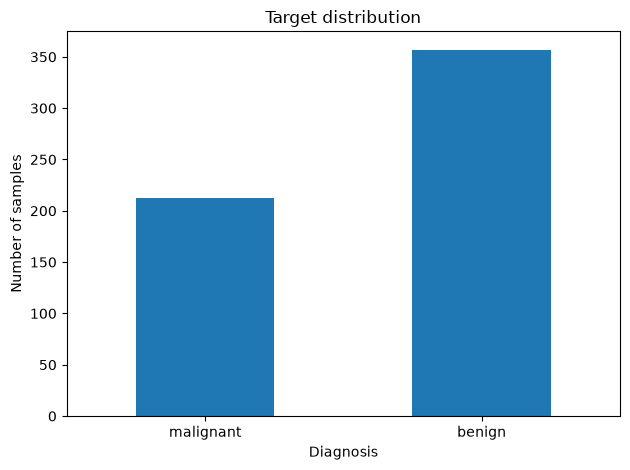

DummyClassifier test accuracy: 0.6257
Train shape: (398, 30) | Test shape: (171, 30)


In [11]:
# Target distribution and one fixed train/test split
ax = y.value_counts().sort_index().rename(index={0: "malignant", 1: "benign"}).plot(
    kind="bar", rot=0, title="Target distribution"
)
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Number of samples")
plt.tight_layout()
plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_test_accuracy = accuracy_score(y_test, dummy.predict(X_test))
print(f"DummyClassifier test accuracy: {dummy_test_accuracy:.4f}")
print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)


In [12]:
# Baseline: scale using training data only, then fit Logistic Regression
baseline_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
t0 = time.perf_counter()
baseline_pipe.fit(X_train, y_train)
baseline_training_time = time.perf_counter() - t0

train_pred = baseline_pipe.predict(X_train)
test_pred = baseline_pipe.predict(X_test)

baseline_metrics = {
    "features": X.shape[1],
    "train_accuracy": accuracy_score(y_train, train_pred),
    "train_f1": f1_score(y_train, train_pred),
    "test_accuracy": accuracy_score(y_test, test_pred),
    "test_f1": f1_score(y_test, test_pred),
    "training_time_s": baseline_training_time
}
display(pd.DataFrame([baseline_metrics]).round(4))


,features,train_accuracy,train_f1,test_accuracy,test_f1,training_time_s
0,30,0.9874,0.9901,0.9883,0.9907,0.0118


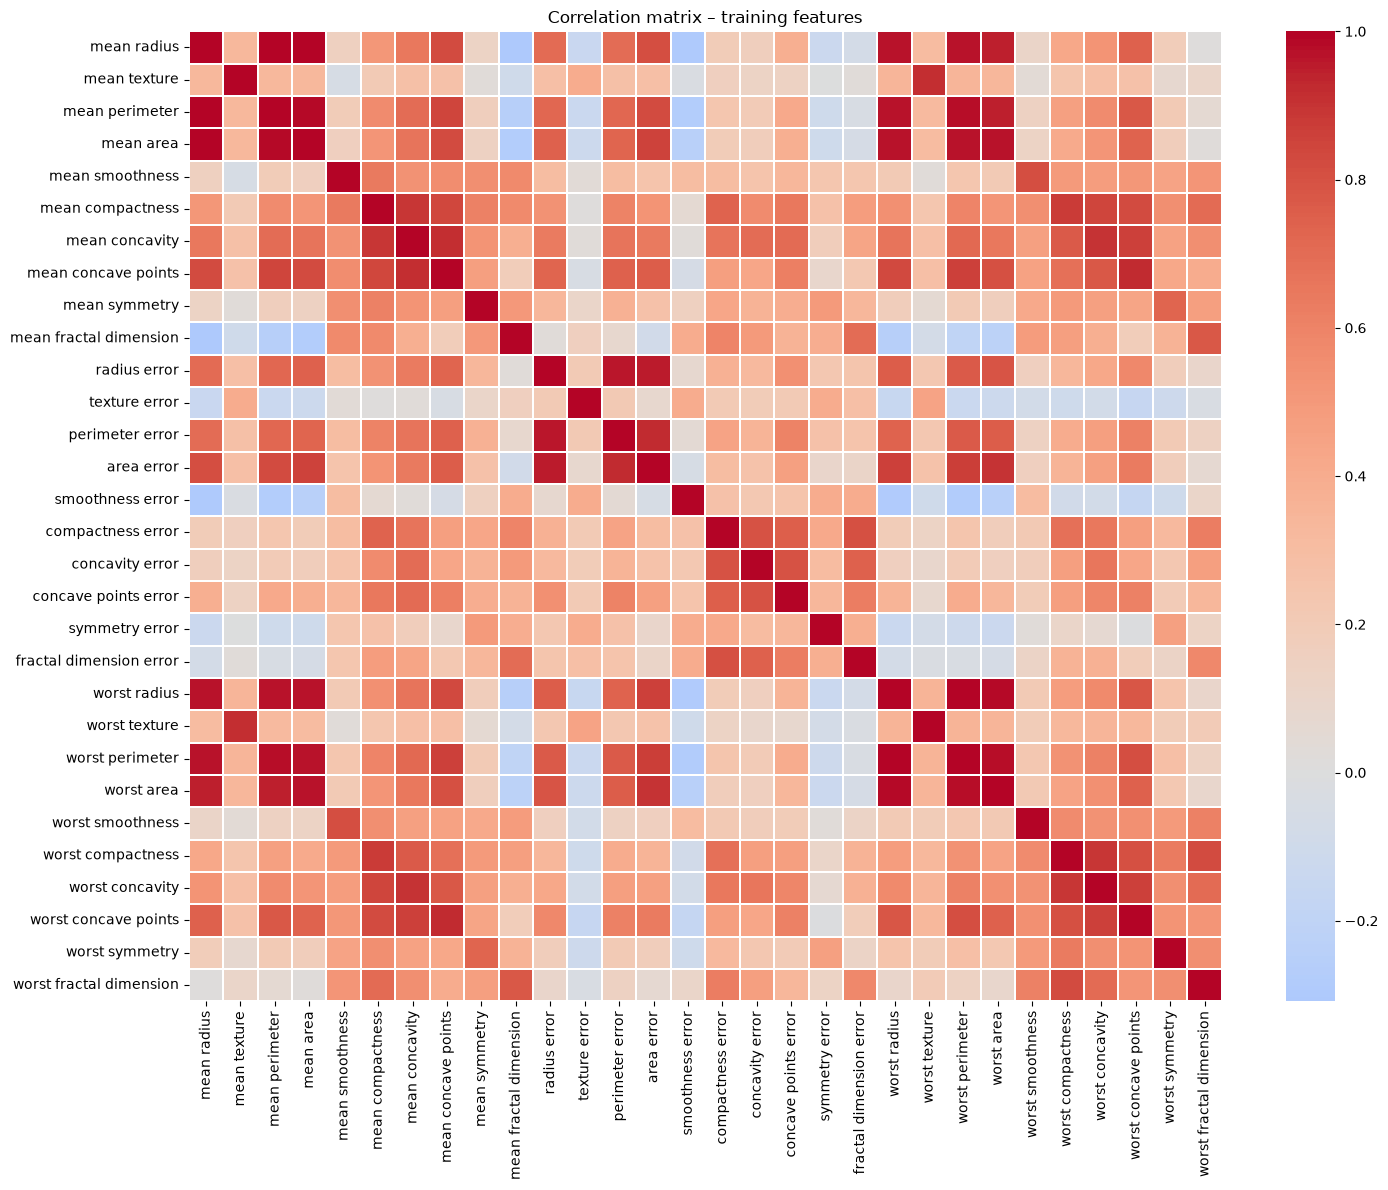

,feature_1,feature_2,abs_correlation
0,mean radius,mean perimeter,0.997803
20,worst radius,worst perimeter,0.993442
1,mean radius,mean area,0.990629
6,mean perimeter,mean area,0.989496
21,worst radius,worst area,0.986020
22,worst perimeter,worst area,0.978478
8,mean perimeter,worst perimeter,0.974864
10,mean area,worst radius,0.974024
2,mean radius,worst radius,0.974018
7,mean perimeter,worst radius,0.973627


In [13]:
# Correlation heatmap on training features
plt.figure(figsize=(15, 12))
sns.heatmap(X_train.corr(), cmap="coolwarm", center=0, linewidths=0.15)
plt.title("Correlation matrix – training features")
plt.tight_layout()
plt.show()

# Show highly correlated pairs (absolute correlation >= 0.90)
corr = X_train.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_pairs = [
    (a, b, upper.loc[a, b])
    for a in upper.index for b in upper.columns
    if pd.notna(upper.loc[a, b]) and upper.loc[a, b] >= 0.90
]
high_pairs_df = pd.DataFrame(high_pairs, columns=["feature_1", "feature_2", "abs_correlation"])
display(high_pairs_df.sort_values("abs_correlation", ascending=False).head(30))


**Part A – interpretation**

- The dataset is suitable for feature selection because it has 30 numerical predictors but many describe closely related geometric properties of the same cell nucleus.
- Strongly correlated variables (for example radius, perimeter and area, including their `mean`, `error` and `worst` versions) contain overlapping information.
- Removing redundant variables can make a model simpler and easier to interpret; it does not guarantee better test performance.

## Part B : Filter methods

In [14]:
# Variance is computed on the original, unscaled training features
variance_table = pd.DataFrame({
    "variance": X_train.var(),
    "removed_at_0": False,
    "removed_at_0.01": X_train.var() <= 0.01,
    "removed_at_0.1": X_train.var() <= 0.1
}).sort_values("variance")
display(variance_table)

variance_rows = []
for threshold in [0, 0.01, 0.1]:
    selector = VarianceThreshold(threshold=threshold)
    selector.fit(X_train)
    kept = int(selector.get_support().sum())
    variance_rows.append({
        "threshold": threshold,
        "remaining_features": kept,
        "removed_features": X_train.shape[1] - kept
    })
variance_results = pd.DataFrame(variance_rows)
display(variance_results)


,variance,removed_at_0,removed_at_0.01,removed_at_0.1
fractal dimension error,0.000008,False,True,True
smoothness error,0.000009,False,True,True
concave points error,0.000040,False,True,True
mean fractal dimension,0.000053,False,True,True
symmetry error,0.000077,False,True,True
mean smoothness,0.000178,False,True,True
compactness error,0.000350,False,True,True
worst fractal dimension,0.000363,False,True,True
worst smoothness,0.000514,False,True,True
mean symmetry,0.000787,False,True,True


,threshold,remaining_features,removed_features
0,0.00,30,0
1,0.01,14,16
2,0.10,11,19


In [16]:
def remove_correlated(X_frame, y_values, threshold):
    X_frame = pd.DataFrame(X_frame).copy()
    y_series = pd.Series(np.asarray(y_values), index=X_frame.index)
    abs_corr = X_frame.corr().abs()
    target_corr = X_frame.apply(lambda col: abs(col.corr(y_series)))
    upper = abs_corr.where(np.triu(np.ones(abs_corr.shape), k=1).astype(bool))
    to_drop = set()

    # Iterate in column order; if a pair is above threshold, discard its
    # less target-associated member (ties: discard the later column).
    for col_j in upper.columns:
        for col_i in upper.index:
            value = upper.loc[col_i, col_j]
            if pd.notna(value) and value > threshold:
                if col_i in to_drop or col_j in to_drop:
                    continue
                if target_corr[col_i] >= target_corr[col_j]:
                    to_drop.add(col_j)
                else:
                    to_drop.add(col_i)

    kept = [c for c in X_frame.columns if c not in to_drop]
    return kept, sorted(to_drop)

correlation_rows = []
correlation_selected = {}
for threshold in [0.95, 0.90, 0.80]:
    kept, dropped = remove_correlated(X_train, y_train, threshold)
    correlation_selected[threshold] = kept
    # Evaluate with CV on training data; do not use the test set before Part D.3.
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ])
    scores = cross_val_score(pipe, X_train[kept], y_train, cv=CV, scoring="accuracy")
    correlation_rows.append({
        "threshold": threshold,
        "remaining_features": len(kept),
        "removed_features": len(dropped),
        "cv_accuracy_mean": scores.mean(),
        "cv_accuracy_std": scores.std()
    })
correlation_results = pd.DataFrame(correlation_rows)
display(correlation_results.round(4))


,threshold,remaining_features,removed_features,cv_accuracy_mean,cv_accuracy_std
0,0.95,23,7,0.9824,0.0189
1,0.90,19,11,0.9698,0.0190
2,0.80,13,17,0.9422,0.0234


,feature,ANOVA_F,ANOVA_p_value,mutual_information
27,worst concave points,732.283255,4.580936e-92,0.458544
22,worst perimeter,643.459905,5.272376e-85,0.480169
7,mean concave points,635.025749,2.652547e-84,0.441150
20,worst radius,617.391336,8.118827e-83,0.456132
2,mean perimeter,519.551421,4.523574e-74,0.408863
23,worst area,486.344354,6.895761e-71,0.453980
0,mean radius,480.594009,2.523353e-70,0.366090
3,mean area,450.499138,2.584797e-67,0.355582
6,mean concavity,365.480510,3.437535e-58,0.361105
26,worst concavity,335.294070,1.057530e-54,0.335338


Spearman correlation between rankings: 0.9657397107897663


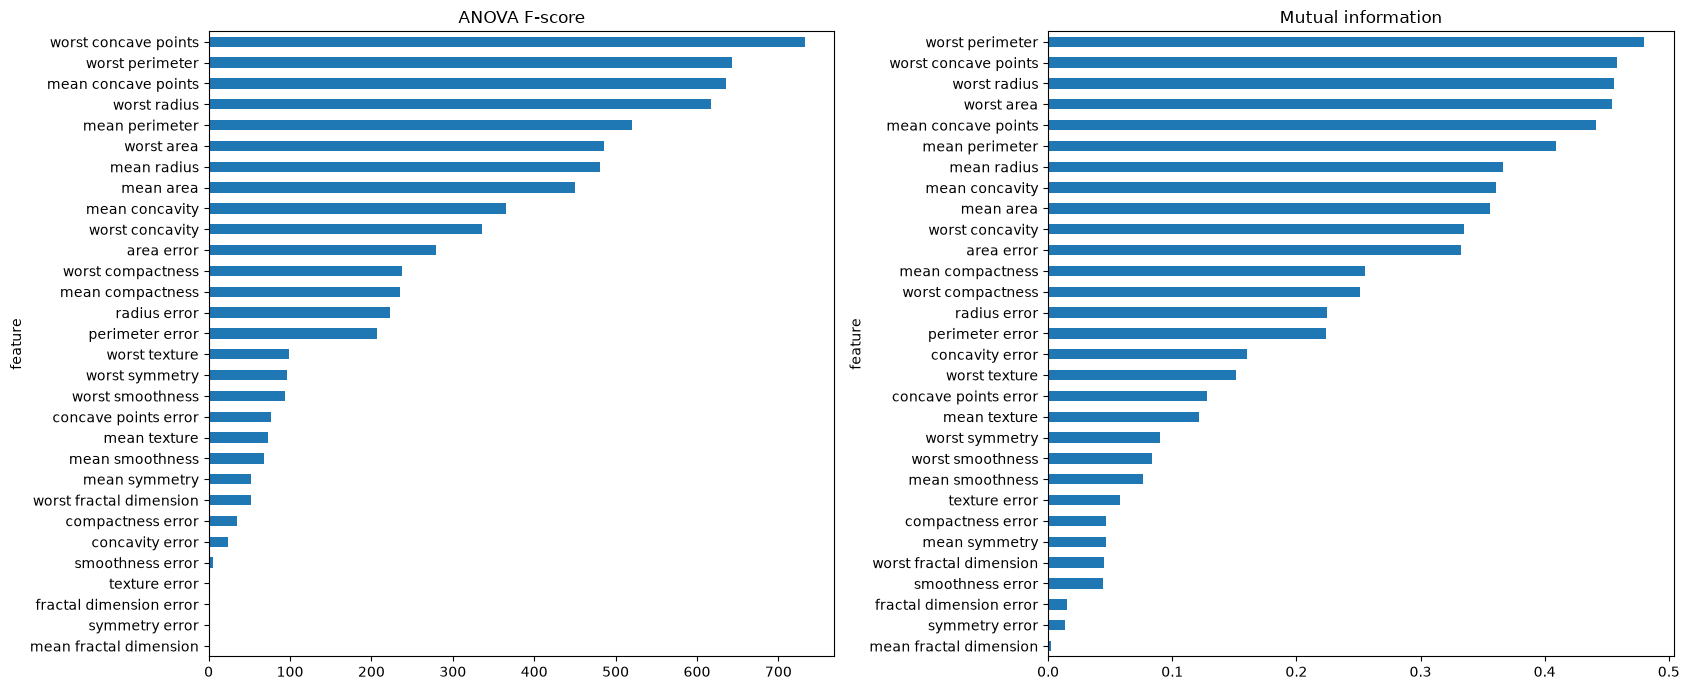

In [17]:
f_scores, f_pvalues = f_classif(X_train, y_train)
mi_scores = mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE)

filter_scores = pd.DataFrame({
    "feature": feature_names,
    "ANOVA_F": f_scores,
    "ANOVA_p_value": f_pvalues,
    "mutual_information": mi_scores
})
display(filter_scores.sort_values("ANOVA_F", ascending=False).head(15))
print("Spearman correlation between rankings:",
      spearmanr(filter_scores["ANOVA_F"], filter_scores["mutual_information"]).statistic)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
filter_scores.sort_values("ANOVA_F").plot.barh(
    x="feature", y="ANOVA_F", ax=axes[0], legend=False, title="ANOVA F-score"
)
filter_scores.sort_values("mutual_information").plot.barh(
    x="feature", y="mutual_information", ax=axes[1],
    legend=False, title="Mutual information"
)
plt.tight_layout()
plt.show()


,score,k,mean_accuracy,std_accuracy
0,ANOVA F-score,2,0.9347,0.0148
1,ANOVA F-score,5,0.9523,0.0146
2,ANOVA F-score,10,0.9523,0.0146
3,ANOVA F-score,15,0.9598,0.0166
4,ANOVA F-score,20,0.9874,0.0139
5,ANOVA F-score,25,0.9824,0.0189
6,ANOVA F-score,30,0.9824,0.0189
7,Mutual information,2,0.9372,0.0306
8,Mutual information,5,0.9548,0.0151
9,Mutual information,10,0.9523,0.0146


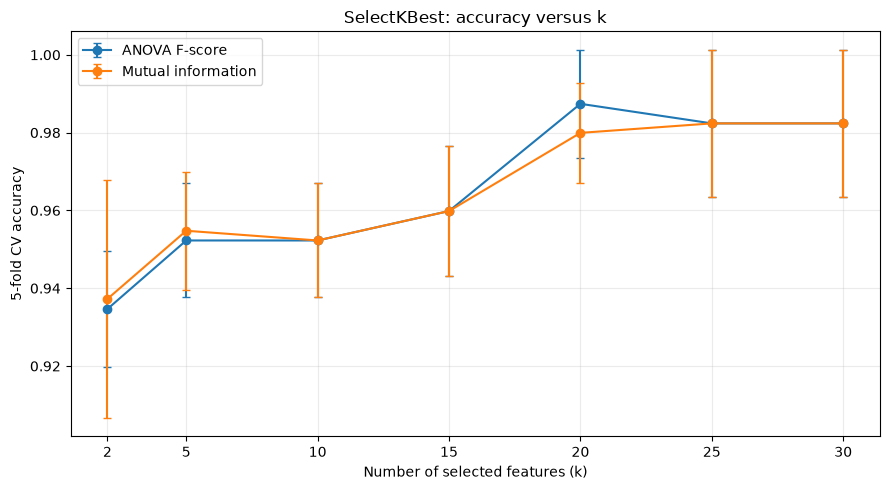

Smallest k within one standard deviation of the best:
{'ANOVA F-score': 20, 'Mutual information': 20}


In [18]:
k_values = [2, 5, 10, 15, 20, 25, 30]
filter_cv_rows = []

for score_name, score_func in [
    ("ANOVA F-score", f_classif),
    ("Mutual information", lambda X_, y_: (
        mutual_info_classif(X_, y_, random_state=RANDOM_STATE), None
    ))
]:
    for k in k_values:
        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("selector", SelectKBest(score_func=score_func, k=k)),
            ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
        ])
        scores = cross_val_score(pipe, X_train, y_train, cv=CV, scoring="accuracy")
        filter_cv_rows.append({
            "score": score_name, "k": k,
            "mean_accuracy": scores.mean(), "std_accuracy": scores.std()
        })

filter_cv_results = pd.DataFrame(filter_cv_rows)
display(filter_cv_results.round(4))

plt.figure(figsize=(9, 5))
for score_name, group in filter_cv_results.groupby("score"):
    plt.errorbar(group["k"], group["mean_accuracy"], yerr=group["std_accuracy"],
                 marker="o", capsize=3, label=score_name)
plt.xlabel("Number of selected features (k)")
plt.ylabel("5-fold CV accuracy")
plt.title("SelectKBest: accuracy versus k")
plt.xticks(k_values)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

def smallest_k_within_one_std(group):
    best_idx = group["mean_accuracy"].idxmax()
    best_mean = group.loc[best_idx, "mean_accuracy"]
    best_std = group.loc[best_idx, "std_accuracy"]
    eligible = group[group["mean_accuracy"] >= best_mean - best_std]
    return int(eligible["k"].min())

best_filter_k = {}
for score_name, group in filter_cv_results.groupby("score"):
    best_filter_k[score_name] = smallest_k_within_one_std(group)
print("Smallest k within one standard deviation of the best:")
print(best_filter_k)


## Part C : Wrapper methods

In [19]:
def make_lr_pipeline():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ])

def cv_accuracy_for_columns(X_frame, y_values, columns):
    scores = cross_val_score(make_lr_pipeline(), X_frame[columns], y_values,
                             cv=CV, scoring="accuracy")
    return scores.mean()

def selected_names(selector, columns):
    return list(np.asarray(columns)[selector.get_support()])


In [20]:
# scikit-learn SequentialFeatureSelector
forward_sfs = SequentialFeatureSelector(
    make_lr_pipeline(), n_features_to_select=10, direction="forward",
    scoring="accuracy", cv=CV, n_jobs=-1
)
t0 = time.perf_counter()
forward_sfs.fit(X_train, y_train)
forward_sfs_time = time.perf_counter() - t0
forward_sfs_features = selected_names(forward_sfs, feature_names)
print("SequentialFeatureSelector forward features:")
print(forward_sfs_features)
print(f"Elapsed time: {forward_sfs_time:.2f} seconds")


SequentialFeatureSelector forward features:
[np.str_('mean radius'), np.str_('mean texture'), np.str_('mean perimeter'), np.str_('mean compactness'), np.str_('texture error'), np.str_('smoothness error'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst perimeter'), np.str_('worst smoothness')]
Elapsed time: 11.53 seconds


,n_features,added_feature,cv_accuracy,gain
0,1,worst radius,0.922120,0.922120
1,2,worst smoothness,0.967342,0.045222
2,3,worst texture,0.982405,0.015063
3,4,mean radius,0.984937,0.002532


Manual forward features: ['worst radius', 'worst smoothness', 'worst texture', 'mean radius']
Same set as sklearn: False
Manual search time: 6.79 seconds


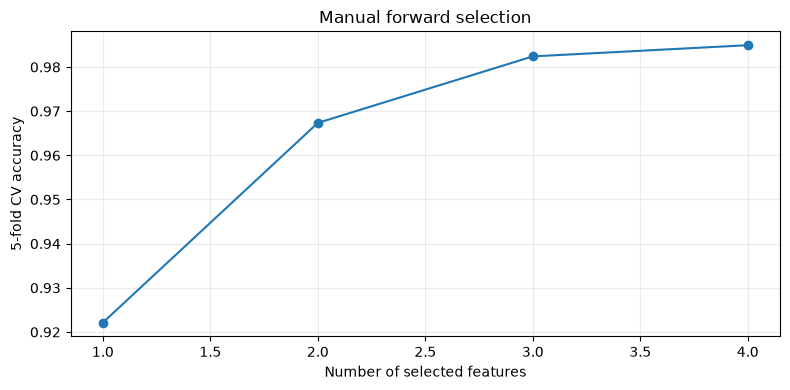

In [21]:
# Manual greedy forward selection with epsilon = 0.001
def manual_forward_selection(X_frame, y_values, max_features=10, epsilon=0.001):
    remaining = list(X_frame.columns)
    selected = []
    history = []
    previous_score = 0.0

    while remaining and len(selected) < max_features:
        candidates = []
        for candidate in remaining:
            trial = selected + [candidate]
            score = cv_accuracy_for_columns(X_frame, y_values, trial)
            candidates.append((score, candidate))
        candidates.sort(key=lambda item: item[0], reverse=True)
        best_score, best_feature = candidates[0]
        gain = best_score - previous_score

        if selected and gain < epsilon:
            break
        selected.append(best_feature)
        remaining.remove(best_feature)
        history.append({
            "n_features": len(selected), "added_feature": best_feature,
            "cv_accuracy": best_score, "gain": gain
        })
        previous_score = best_score
    return selected, pd.DataFrame(history)

t0 = time.perf_counter()
manual_forward_features, forward_history = manual_forward_selection(X_train, y_train)
manual_forward_time = time.perf_counter() - t0
display(forward_history)
print("Manual forward features:", manual_forward_features)
print("Same set as sklearn:", set(manual_forward_features) == set(forward_sfs_features))
print(f"Manual search time: {manual_forward_time:.2f} seconds")

plt.figure(figsize=(8, 4))
plt.plot(forward_history["n_features"], forward_history["cv_accuracy"], marker="o")
plt.xlabel("Number of selected features")
plt.ylabel("5-fold CV accuracy")
plt.title("Manual forward selection")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [22]:
backward_sfs = SequentialFeatureSelector(
    make_lr_pipeline(), n_features_to_select=10, direction="backward",
    scoring="accuracy", cv=CV, n_jobs=-1
)
t0 = time.perf_counter()
backward_sfs.fit(X_train, y_train)
backward_sfs_time = time.perf_counter() - t0
backward_sfs_features = selected_names(backward_sfs, feature_names)
print("SequentialFeatureSelector backward features:")
print(backward_sfs_features)
print(f"Elapsed time: {backward_sfs_time:.2f} seconds")


SequentialFeatureSelector backward features:
[np.str_('area error'), np.str_('smoothness error'), np.str_('fractal dimension error'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst perimeter'), np.str_('worst area'), np.str_('worst smoothness'), np.str_('worst concavity'), np.str_('worst symmetry')]
Elapsed time: 11.90 seconds


,n_features,removed_feature,cv_accuracy
0,30,NaN,0.982373
1,29,mean radius,0.982373
2,28,mean perimeter,0.982373
3,27,mean texture,0.984905
4,26,worst concave points,0.987405
5,25,mean symmetry,0.987405
6,24,concave points error,0.989937
7,23,mean smoothness,0.989937
8,22,mean compactness,0.989937
9,21,radius error,0.989937


Manual backward features: ['area error', 'smoothness error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst concavity', 'worst symmetry']
Same set as sklearn: True
Manual search time: 20.49 seconds


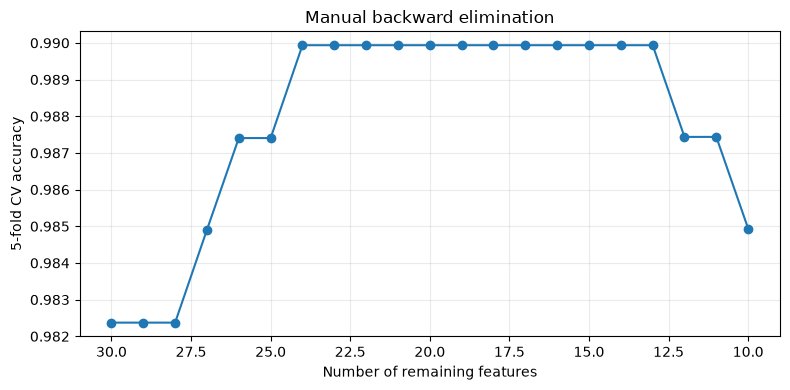

Forward / backward intersection: [np.str_('smoothness error'), np.str_('worst perimeter'), np.str_('worst radius'), np.str_('worst smoothness'), np.str_('worst texture')]


In [23]:
# Manual backward elimination: remove the feature whose removal gives
# the highest remaining CV accuracy (least degradation).
def manual_backward_elimination(X_frame, y_values, n_features_to_keep=10):
    remaining = list(X_frame.columns)
    history = [{
        "n_features": len(remaining),
        "removed_feature": None,
        "cv_accuracy": cv_accuracy_for_columns(X_frame, y_values, remaining)
    }]

    while len(remaining) > n_features_to_keep:
        candidates = []
        for feature in remaining:
            trial = [c for c in remaining if c != feature]
            score = cv_accuracy_for_columns(X_frame, y_values, trial)
            candidates.append((score, feature))
        candidates.sort(key=lambda item: item[0], reverse=True)
        best_score, removed = candidates[0]
        remaining.remove(removed)
        history.append({
            "n_features": len(remaining),
            "removed_feature": removed,
            "cv_accuracy": best_score
        })
    return remaining, pd.DataFrame(history)

t0 = time.perf_counter()
manual_backward_features, backward_history = manual_backward_elimination(
    X_train, y_train, n_features_to_keep=10
)
manual_backward_time = time.perf_counter() - t0
display(backward_history)
print("Manual backward features:", manual_backward_features)
print("Same set as sklearn:", set(manual_backward_features) == set(backward_sfs_features))
print(f"Manual search time: {manual_backward_time:.2f} seconds")

plt.figure(figsize=(8, 4))
plt.plot(backward_history["n_features"], backward_history["cv_accuracy"], marker="o")
plt.xlabel("Number of remaining features")
plt.ylabel("5-fold CV accuracy")
plt.title("Manual backward elimination")
plt.gca().invert_xaxis()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Forward / backward intersection:",
      sorted(set(forward_sfs_features) & set(backward_sfs_features)))


In [24]:
rfe = RFE(
    estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    n_features_to_select=10
)
rfe.fit(StandardScaler().fit_transform(X_train), y_train)
rfe_features = list(np.asarray(feature_names)[rfe.support_])
rfe_details = pd.DataFrame({
    "feature": feature_names,
    "selected": rfe.support_,
    "ranking": rfe.ranking_
}).sort_values(["ranking", "feature"])
display(rfe_details)
print("RFE selected features:", rfe_features)


,feature,selected,ranking
13,area error,True,1
3,mean area,True,1
7,mean concave points,True,1
23,worst area,True,1
27,worst concave points,True,1
22,worst perimeter,True,1
20,worst radius,True,1
24,worst smoothness,True,1
28,worst symmetry,True,1
21,worst texture,True,1


RFE selected features: [np.str_('mean area'), np.str_('mean concave points'), np.str_('area error'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst perimeter'), np.str_('worst area'), np.str_('worst smoothness'), np.str_('worst concave points'), np.str_('worst symmetry')]


RFECV optimal number of features: 8
RFECV selected features: [np.str_('mean area'), np.str_('area error'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst perimeter'), np.str_('worst area'), np.str_('worst smoothness'), np.str_('worst concave points')]
RFECV time: 0.54 seconds


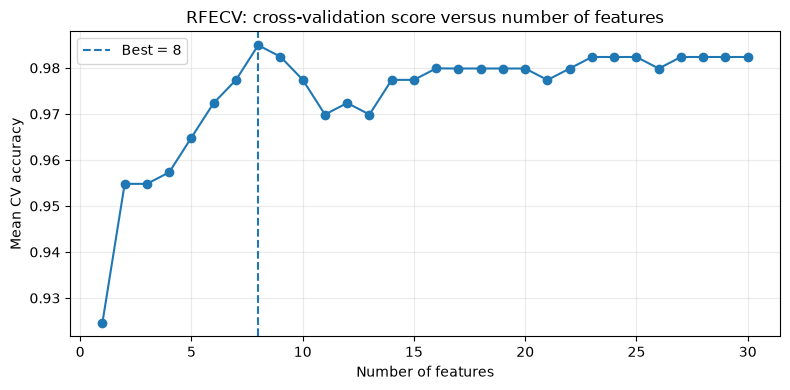

In [25]:
rfecv = RFECV(
    estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    step=1, cv=CV, scoring="accuracy", min_features_to_select=1, n_jobs=-1
)
t0 = time.perf_counter()
rfecv.fit(StandardScaler().fit_transform(X_train), y_train)
rfecv_time = time.perf_counter() - t0
rfecv_features = list(np.asarray(feature_names)[rfecv.support_])
print("RFECV optimal number of features:", rfecv.n_features_)
print("RFECV selected features:", rfecv_features)
print(f"RFECV time: {rfecv_time:.2f} seconds")

# Compatibility across scikit-learn versions
rfecv_scores = getattr(rfecv, "cv_results_", {}).get("mean_test_score")
if rfecv_scores is not None:
    n_values = np.arange(rfecv.min_features_to_select,
                         rfecv.min_features_to_select + len(rfecv_scores))
    plt.figure(figsize=(8, 4))
    plt.plot(n_values, rfecv_scores, marker="o")
    plt.axvline(rfecv.n_features_, linestyle="--", label=f"Best = {rfecv.n_features_}")
    plt.xlabel("Number of features")
    plt.ylabel("Mean CV accuracy")
    plt.title("RFECV: cross-validation score versus number of features")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print("RFECV scores are not exposed by this scikit-learn version.")


In [26]:
# Repeat RFE with a linear SVM estimator
rfe_svc = RFE(estimator=SVC(kernel="linear"), n_features_to_select=10)
rfe_svc.fit(StandardScaler().fit_transform(X_train), y_train)
rfe_svc_features = list(np.asarray(feature_names)[rfe_svc.support_])
print("Logistic Regression RFE:", rfe_features)
print("Linear SVC RFE:", rfe_svc_features)
print("Intersection:", sorted(set(rfe_features) & set(rfe_svc_features)))


Logistic Regression RFE: [np.str_('mean area'), np.str_('mean concave points'), np.str_('area error'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst perimeter'), np.str_('worst area'), np.str_('worst smoothness'), np.str_('worst concave points'), np.str_('worst symmetry')]
Linear SVC RFE: [np.str_('area error'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst perimeter'), np.str_('worst area'), np.str_('worst smoothness'), np.str_('worst compactness'), np.str_('worst concavity'), np.str_('worst concave points'), np.str_('worst symmetry')]
Intersection: [np.str_('area error'), np.str_('worst area'), np.str_('worst concave points'), np.str_('worst perimeter'), np.str_('worst radius'), np.str_('worst smoothness'), np.str_('worst symmetry'), np.str_('worst texture')]


In [27]:
p = X_train.shape[1]
k = 10
candidate_evaluations = sum(p - i for i in range(k))
cv_model_fits = candidate_evaluations * CV.get_n_splits()
exhaustive_subsets = sum(math.comb(p, j) for j in range(1, k + 1))
print(f"Forward candidate subsets evaluated: {candidate_evaluations}")
print(f"Forward model fits with 5-fold CV: {cv_model_fits}")
print(f"Exhaustive subsets of sizes 1..{k}: {exhaustive_subsets:,}")
print(f"Exhaustive model fits with 5-fold CV: {exhaustive_subsets * 5:,}")
print(f"Measured manual forward time: {manual_forward_time:.2f} seconds")
print(f"Measured sklearn forward time: {forward_sfs_time:.2f} seconds")


Forward candidate subsets evaluated: 255
Forward model fits with 5-fold CV: 1275
Exhaustive subsets of sizes 1..10: 53,009,101
Exhaustive model fits with 5-fold CV: 265,045,505
Measured manual forward time: 6.79 seconds
Measured sklearn forward time: 11.53 seconds


## Part D : Noise injection and leakage and final comparison

In [28]:
# Add the same reproducible 20 independent standard-normal noise columns
rng = np.random.default_rng(42)
noise_train = pd.DataFrame(
    rng.standard_normal((len(X_train), 20)),
    index=X_train.index,
    columns=[f"noise_{i:02d}" for i in range(20)]
)
noise_test = pd.DataFrame(
    rng.standard_normal((len(X_test), 20)),
    index=X_test.index,
    columns=[f"noise_{i:02d}" for i in range(20)]
)
# The TP specifies draws for train and test; generate each split separately
X_train_50 = pd.concat([X_train, noise_train], axis=1)
X_test_50 = pd.concat([X_test, noise_test], axis=1)
features_50 = X_train_50.columns.tolist()
noise_names = [f"noise_{i:02d}" for i in range(20)]
print("Training shape with noise:", X_train_50.shape)
print("Testing shape with noise:", X_test_50.shape)


Training shape with noise: (398, 50)
Testing shape with noise: (171, 50)


In [29]:
# SelectKBest (F-score), k=10
skb_noise = SelectKBest(score_func=f_classif, k=10)
skb_noise.fit(X_train_50, y_train)
noise_filter_features = list(np.asarray(features_50)[skb_noise.get_support()])

# Forward and backward selection on the 50-feature training set.
# These are deliberately computationally expensive.
forward_50 = SequentialFeatureSelector(
    make_lr_pipeline(), n_features_to_select=10, direction="forward",
    scoring="accuracy", cv=CV, n_jobs=-1
)
t0 = time.perf_counter()
forward_50.fit(X_train_50, y_train)
forward_50_time = time.perf_counter() - t0
forward_50_features = selected_names(forward_50, features_50)

backward_50 = SequentialFeatureSelector(
    make_lr_pipeline(), n_features_to_select=10, direction="backward",
    scoring="accuracy", cv=CV, n_jobs=-1
)
t0 = time.perf_counter()
backward_50.fit(X_train_50, y_train)
backward_50_time = time.perf_counter() - t0
backward_50_features = selected_names(backward_50, features_50)

# RFE with logistic regression on standardized training data
rfe_50 = RFE(
    estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    n_features_to_select=10
)
rfe_50.fit(StandardScaler().fit_transform(X_train_50), y_train)
rfe_50_features = list(np.asarray(features_50)[rfe_50.support_])

noise_selection = {
    "SelectKBest F-score": noise_filter_features,
    "Forward Selection": forward_50_features,
    "Backward Elimination": backward_50_features,
    "RFE": rfe_50_features
}
noise_summary = pd.DataFrame([
    {
        "method": method,
        "selected_features": selected,
        "number_of_noise_features": sum(f in noise_names for f in selected)
    }
    for method, selected in noise_selection.items()
])
display(noise_summary)


,method,selected_features,number_of_noise_features
0,SelectKBest F-score,"[mean radius, mean perimeter, mean area, mean ...",0
1,Forward Selection,"[mean radius, mean texture, mean perimeter, me...",0
2,Backward Elimination,"[area error, compactness error, worst texture,...",5
3,RFE,"[mean area, mean concave points, area error, w...",0


In [30]:
# Incorrect estimate: select features once using all training observations,
# then cross-validate the classifier on this already-selected matrix.
leaky_selector = SelectKBest(score_func=f_classif, k=10)
X_train_selected_leaky = leaky_selector.fit_transform(X_train_50, y_train)
leaky_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
leaky_scores = cross_val_score(
    leaky_pipe, X_train_selected_leaky, y_train, cv=CV, scoring="accuracy"
)

# Correct estimate: selector and scaler are refitted within every CV fold.
correct_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(score_func=f_classif, k=10)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
correct_scores = cross_val_score(
    correct_pipe, X_train_50, y_train, cv=CV, scoring="accuracy"
)

leakage_results = pd.DataFrame([
    {"procedure": "Incorrect: selection before CV",
     "mean_cv_accuracy": leaky_scores.mean(), "std": leaky_scores.std()},
    {"procedure": "Correct: selection inside Pipeline",
     "mean_cv_accuracy": correct_scores.mean(), "std": correct_scores.std()}
])
display(leakage_results.round(4))


,procedure,mean_cv_accuracy,std
0,Incorrect: selection before CV,0.9523,0.0146
1,Correct: selection inside Pipeline,0.9523,0.0146


In [31]:
# Choose k values using the training-set CV results from Part B.
k_f = best_filter_k.get("ANOVA F-score", 10)
k_mi = best_filter_k.get("Mutual information", 10)

# Correlation filter threshold chosen by best mean CV accuracy in B.2
best_corr_row = correlation_results.loc[correlation_results["cv_accuracy_mean"].idxmax()]
best_corr_threshold = float(best_corr_row["threshold"])
best_corr_features = correlation_selected[best_corr_threshold]

# Build final pipelines. Selection and scaling are fit only on training data.
final_methods = {
    "Filter: correlation": (
        Pipeline([("scaler", StandardScaler()),
                  ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
        best_corr_features
    ),
    "Filter: SelectKBest, F-score": (
        Pipeline([("scaler", StandardScaler()),
                  ("selector", SelectKBest(f_classif, k=k_f)),
                  ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
        None
    ),
    "Filter: SelectKBest, mutual information": (
        Pipeline([("scaler", StandardScaler()),
                  ("selector", SelectKBest(
                      lambda X_, y_: mutual_info_classif(X_, y_, random_state=RANDOM_STATE),
                      k=k_mi)),
                  ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
        None
    ),
    "Wrapper: Forward Selection": (
        Pipeline([("scaler", StandardScaler()),
                  ("selector", SequentialFeatureSelector(
                      make_lr_pipeline(), n_features_to_select=10,
                      direction="forward", scoring="accuracy", cv=CV, n_jobs=-1)),
                  ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
        None
    ),
    "Wrapper: Backward Elimination": (
        Pipeline([("scaler", StandardScaler()),
                  ("selector", SequentialFeatureSelector(
                      make_lr_pipeline(), n_features_to_select=10,
                      direction="backward", scoring="accuracy", cv=CV, n_jobs=-1)),
                  ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
        None
    ),
    "Wrapper: RFE": (
        Pipeline([("scaler", StandardScaler()),
                  ("selector", RFE(
                      LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
                      n_features_to_select=10)),
                  ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
        None
    ),
    "Wrapper: RFECV": (
        Pipeline([("scaler", StandardScaler()),
                  ("selector", RFECV(
                      LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
                      step=1, cv=CV, scoring="accuracy", min_features_to_select=1, n_jobs=-1)),
                  ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
        None
    )
}

final_rows = [{
    "method": "Baseline (all features)", "n_features": 30,
    "test_accuracy": baseline_metrics["test_accuracy"],
    "test_f1": baseline_metrics["test_f1"],
    "selection_time_s": np.nan
}]
final_selected_features = {"Baseline (all features)": feature_names}

for method_name, (pipe, fixed_columns) in final_methods.items():
    t0 = time.perf_counter()
    if fixed_columns is not None:
        pipe.fit(X_train[fixed_columns], y_train)
        pred = pipe.predict(X_test[fixed_columns])
        chosen = list(fixed_columns)
    else:
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        selector = pipe.named_steps["selector"]
        chosen = list(np.asarray(feature_names)[selector.get_support()])
    elapsed = time.perf_counter() - t0
    final_selected_features[method_name] = chosen
    final_rows.append({
        "method": method_name,
        "n_features": len(chosen),
        "test_accuracy": accuracy_score(y_test, pred),
        "test_f1": f1_score(y_test, pred),
        "selection_time_s": elapsed
    })

final_results = pd.DataFrame(final_rows)
display(final_results.round(4))


,method,n_features,test_accuracy,test_f1,selection_time_s
0,Baseline (all features),30,0.9883,0.9907,NaN
1,Filter: correlation,23,0.9825,0.9860,0.0167
2,"Filter: SelectKBest, F-score",20,0.9766,0.9813,0.0128
3,"Filter: SelectKBest, mutual information",20,0.9708,0.9770,0.0728
4,Wrapper: Forward Selection,10,0.9357,0.9484,8.6743
5,Wrapper: Backward Elimination,10,0.9649,0.9722,10.6416
6,Wrapper: RFE,10,0.9708,0.9767,0.0722
7,Wrapper: RFECV,8,0.9591,0.9671,0.3868


In [33]:
# Presence matrix: rows are features, columns are methods
features = feature_names

presence = pd.DataFrame(
    {
        method: [feature in selected for feature in features]
        for method, selected in final_selected_features.items()
    },
    index=features
)

display(presence.astype(int))

selected_by_all = presence.index[presence.all(axis=1)].tolist()

print("Features selected by every final method:", selected_by_all)

# Also list selected features for each method
for method, selected in final_selected_features.items():
    print(f"\n{method} ({len(selected)}):")
    print(", ".join(selected))


,Baseline (all features),Filter: correlation,"Filter: SelectKBest, F-score","Filter: SelectKBest, mutual information",Wrapper: Forward Selection,Wrapper: Backward Elimination,Wrapper: RFE,Wrapper: RFECV
mean radius,1,0,1,1,1,0,0,0
mean texture,1,1,1,1,1,0,0,0
mean perimeter,1,0,1,1,1,0,0,0
mean area,1,0,1,1,0,0,1,1
mean smoothness,1,1,0,0,0,0,0,0
mean compactness,1,1,1,1,1,0,0,0
mean concavity,1,1,1,1,0,0,0,0
mean concave points,1,1,1,1,0,0,1,0
mean symmetry,1,1,0,0,0,0,0,0
mean fractal dimension,1,1,0,0,0,0,0,0


Features selected by every final method: ['worst texture', 'worst perimeter']

Baseline (all features) (30):
mean radius, mean texture, mean perimeter, mean area, mean smoothness, mean compactness, mean concavity, mean concave points, mean symmetry, mean fractal dimension, radius error, texture error, perimeter error, area error, smoothness error, compactness error, concavity error, concave points error, symmetry error, fractal dimension error, worst radius, worst texture, worst perimeter, worst area, worst smoothness, worst compactness, worst concavity, worst concave points, worst symmetry, worst fractal dimension

Filter: correlation (23):
mean texture, mean smoothness, mean compactness, mean concavity, mean concave points, mean symmetry, mean fractal dimension, texture error, area error, smoothness error, compactness error, concavity error, concave points error, symmetry error, fractal dimension error, worst texture, worst perimeter, worst smoothness, worst compactness, worst concav

In [34]:
# A few data-driven facts to support the written discussion
best_final = final_results.sort_values(
    ["test_accuracy", "n_features"], ascending=[False, True]
).iloc[0]
baseline_row = final_results[final_results["method"] == "Baseline (all features)"].iloc[0]
print("Best accuracy / fewest-feature row (sorting by accuracy then feature count):")
display(best_final.to_frame("value"))
print(f"Baseline test accuracy: {baseline_row['test_accuracy']:.4f}")
print(f"Best row test accuracy: {best_final['test_accuracy']:.4f}")
print(f"Absolute difference: {best_final['test_accuracy'] - baseline_row['test_accuracy']:.4f}")
print("Test-set size:", len(y_test))
print("Forward-selection candidate subsets (30 features, 10 selected):",
      sum(30 - i for i in range(10)))
print("Forward-selection CV model fits:", sum(30 - i for i in range(10)) * 5)


Best accuracy / fewest-feature row (sorting by accuracy then feature count):


,value
method,Baseline (all features)
n_features,30
test_accuracy,0.988304
test_f1,0.990654
selection_time_s,NaN


Baseline test accuracy: 0.9883
Best row test accuracy: 0.9883
Absolute difference: 0.0000
Test-set size: 171
Forward-selection candidate subsets (30 features, 10 selected): 255
Forward-selection CV model fits: 1275
